# Representación del Conocimiento en ABM

En los Modelos Basados en Agentes (**ABM**, por sus siglas en inglés), la **representación del conocimiento** se refiere a la forma en que se modela y estructura la información que los agentes necesitan para tomar decisiones y actuar en su entorno. Esta representación es crucial para simular comportamientos realistas y para que los agentes puedan percibir, procesar y responder de manera adecuada a los cambios en el entorno y a las interacciones con otros agentes.



## Componentes Clave de la Representación del Conocimiento en ABM

1. **Memoria**:
   - Los agentes pueden tener una "memoria" que les permite recordar información pasada, como la posición de recursos, rutas seguras, o la identidad de otros agentes con los que han interactuado.
   - Esto es fundamental en simulaciones de comportamiento complejo, donde los agentes pueden necesitar recordar experiencias pasadas para tomar mejores decisiones en el futuro.

2. **Percepción**:
   - La percepción representa la información que los agentes pueden "ver" o "sentir" en su entorno inmediato.
   - Esto puede ser el estado de las celdas adyacentes en una cuadrícula, la proximidad de otros agentes, o la disponibilidad de recursos en su vecindario.
   - La percepción determina la cantidad y tipo de conocimiento al que el agente tiene acceso para tomar decisiones.

3. **Creencias y Conocimiento**:
   - En algunos modelos, los agentes tienen representaciones de "creencias" o conocimientos sobre el entorno y otros agentes.
   - Estas creencias pueden estar basadas en su experiencia o en la información compartida por otros agentes y pueden ayudar a simular fenómenos como el aprendizaje y la toma de decisiones basada en información incompleta o incierta.

4. **Objetivos y Preferencias**:
   - Los agentes suelen tener objetivos específicos (por ejemplo, llegar a un lugar o recolectar recursos) y preferencias que guían sus decisiones.
   - Estos objetivos y preferencias influyen en cómo interpretan su conocimiento y en la forma en que priorizan diferentes opciones.

5. **Reglas de Decisión y Heurísticas**:
   - Los agentes pueden emplear reglas de decisión, como algoritmos de búsqueda o reglas heurísticas, para procesar la información y decidir su siguiente acción.
   - Estas reglas pueden estar basadas en el conocimiento del agente y permiten simplificar decisiones complejas (por ejemplo, "si el recurso más cercano está a menos de 5 unidades, entonces moverme hacia él").



### Ejemplos de Representación de Conocimiento en ABM

Imagina un modelo donde varios agentes son exploradores que buscan comida en un bosque:

1. **Percepción**:
   - Cada agente puede percibir el terreno y detectar si hay comida en las celdas vecinas.

2. **Memoria**:
   - El agente recuerda los lugares donde encontró comida anteriormente, de modo que puede regresar si no encuentra nuevas fuentes.

3. **Creencias**:
   - El agente cree que ciertos caminos son seguros porque otros agentes informaron que no hay depredadores en esas áreas.

4. **Objetivos y Preferencias**:
   - El agente prioriza la búsqueda de comida antes de volver al refugio, y prefiere ir hacia áreas con una mayor densidad de comida.

5. **Reglas de Decisión**:
   - Si la comida se encuentra en una celda adyacente, el agente se moverá hacia ella; si no, buscará en una dirección basada en la última ubicación de comida.



## Implementación en ABM

En la práctica, el conocimiento de los agentes se puede representar mediante estructuras de datos como:

- **Listas o diccionarios** para almacenar la memoria de ubicaciones de recursos.
- **Variables booleanas** para representar creencias ("zona segura" o "zona peligrosa").
- **Vectores o matrices** para simular el campo de percepción, donde se almacena información sobre el entorno inmediato.



## Importancia en ABM

La representación de conocimiento en ABM es fundamental para:
- **Simular comportamientos complejos** y realistas.
- **Permitir la toma de decisiones basada en experiencias pasadas** y en el conocimiento acumulado.
- **Fomentar la adaptabilidad** de los agentes en entornos dinámicos, permitiéndoles modificar su comportamiento en función del conocimiento percibido y recordado.

Esta estructura permite que los agentes actúen de forma autónoma y adaptable, lo cual es esencial en simulaciones que buscan modelar comportamientos realistas, como el movimiento de animales, la toma de decisiones en humanos, o la colaboración en sistemas de inteligencia artificial.

## Ejemplo: Explorador en Busca de Comida

En este modelo, varios agentes (representados como exploradores) buscan comida en un entorno de cuadrícula. Cada agente recuerda las posiciones donde ha encontrado comida anteriormente y decide moverse en función de su conocimiento.

**Descripción del modelo**

*Agentes*: Exploradores que buscan comida.

*Entorno*: Un grid (cuadrícula) donde hay comida en algunas celdas.

*Memoria*: Los agentes recuerdan las posiciones donde encontraron comida.

*Decisión*: Los agentes se moverán hacia la comida más cercana que han encontrado en el pasado.



### Implementación en Python

1. **Clases de Agentes**:
   - **FoodAgent**: Representa la comida en el entorno. En este modelo, simplemente se colocan en posiciones aleatorias de la cuadrícula.
   - **ExplorerAgent**: Representa los exploradores. Cada explorador tiene una memoria donde almacena las posiciones donde encontró comida. En cada paso, busca comida en su celda actual y se mueve hacia una posición de comida conocida o aleatoriamente.

2. **Métodos en ExplorerAgent**:
   - `step()`: Este método determina la acción del explorador en cada paso. Busca comida, la recuerda, y decide su siguiente movimiento basado en su memoria o se mueve aleatoriamente.
   - `move_towards()`: Mueve al explorador hacia una posición de comida conocida.
   - `random_move()`: Mueve al explorador a una posición aleatoria adyacente.

3. **Modelo FoodModel**:
   - Inicializa el modelo con un número específico de exploradores y comida.
   - Coloca los exploradores y la comida en posiciones aleatorias en la cuadrícula.

4. **Ejecución del Modelo**:
   - Se crean instancias del modelo y se ejecutan 10 pasos, durante los cuales los exploradores intentan encontrar comida y moverse.


### Implementación

Cuando se ejecuta el modelo, verás impresiones en la consola cada vez que un explorador encuentra comida, indicando la posición donde fue encontrada. Esto demuestra cómo los exploradores utilizan la representación del conocimiento (memoria) para tomar decisiones sobre su movimiento en el entorno.

Este ejemplo simple ilustra los conceptos de memoria, percepción y toma de decisiones en un contexto de ABM, y cómo se pueden implementar utilizando la librería Mesa en Python.

In [37]:
%pip install mesa --quiet

/Users/oh/World/External/Study/UR/IAPS-I/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [38]:
import random

from mesa import Agent, Model
from mesa.space import MultiGrid

Este notebook funciona con la versión 3.5.1 de mesa

In [39]:
import mesa

print(mesa.__version__)

3.5.1


In [40]:
class FoodAgent(Agent):
    """Un agente que representa la comida en el entorno."""
    def __init__(self, model):
        super().__init__(model)

class ExplorerAgent(Agent):
    """Un agente que representa un explorador que busca comida."""
    def __init__(self, model):
        super().__init__(model)
        self.memory = []  # Memoria de posiciones donde encontró comida

    def step(self):
        """Realiza un movimiento en busca de comida."""
        # Verifica si hay comida en la posición actual
        cell_contents: list[FoodAgent] = self.model.grid.get_neighbors(self.pos, moore=True, include_center=True)
        food_found = any(isinstance(agent, FoodAgent) for agent in cell_contents)

        if food_found:
            # Si encuentra comida, la recuerda (solo si no está ya en memoria)
            if self.pos not in self.memory:
                self.memory.append(self.pos)
            print(f"Explorer {self.unique_id} found food at {self.pos}")

        # Decide el siguiente movimiento
        if self.memory:  # Si hay posiciones recordadas
            target_position = random.choice(self.memory)  # Escoge una posición de la memoria
            self.move_towards(target_position)
        else:
            # Moverse aleatoriamente si no hay memoria
            self.random_move()

    def move_towards(self, target_pos):
        """Moverse hacia una posición específica, con verificación de límites."""
        x, y = self.pos
        target_x, target_y = target_pos
        width = self.model.grid.width
        height = self.model.grid.height

        # Dirección hacia el target, pero clamp a límites (condicional encadenada)
        # dx = 1 if x < target_x else -1 if x > target_x else 0
        # dy = 1 if y < target_y else -1 if y > target_y else 0
        # new_x = max(0, min(width - 1, x + dx))
        # new_y = max(0, min(height - 1, y + dy))
        x %= width
        y %= height

        # Mover si es una posición nueva
        if (x, y) != self.pos:
            self.move_to((x, y))
        else:
            self.random_move()

    def random_move(self):
        """Moverse aleatoriamente en la cuadrícula."""
        possible_steps = self.model.grid.get_neighborhood(self.pos, moore=True, include_center=False)
        if possible_steps:
            new_position = random.choice(possible_steps)
            self.move_to(new_position)

    def move_to(self, new_position):
        """Mover el agente a una nueva posición."""
        self.model.grid.move_agent(self, new_position)

class FoodModel(Model):
    """Modelo que contiene los agentes exploradores y la comida."""
    def __init__(self, N, width, height):
        super().__init__()  # Inicializa self.random y self.agents automáticamente
        self.num_agents = N
        self.grid = MultiGrid(width, height, True)  # True para torus (opcional)

        # Crear agentes de comida (auto-agregados a self.agents, pero step() hace pass)
        for _ in range(10):  # Colocar 10 piezas de comida
            food_agent = FoodAgent(self)
            x = self.random.randrange(self.grid.width)
            y = self.random.randrange(self.grid.height)
            self.grid.place_agent(food_agent, (x, y))

        # Crear agentes exploradores (auto-agregados a self.agents)
        for _ in range(self.num_agents):
            explorer_agent = ExplorerAgent(self)
            x = self.random.randrange(self.grid.width)
            y = self.random.randrange(self.grid.height)
            self.grid.place_agent(explorer_agent, (x, y))

    def step(self):
        """Realiza un paso en el modelo."""
        self.agents.shuffle_do("step")  # Equivalente a RandomActivation: mezcla y ejecuta step()


In [41]:
# Crear y ejecutar el modelo
model = FoodModel(N=5, width=10, height=10)

for _ in range(10):  # Realiza 10 pasos
    model.step()

Explorer 12 found food at (3, 4)
Explorer 12 found food at (3, 5)
Explorer 12 found food at (4, 5)
Explorer 14 found food at (6, 0)
Explorer 15 found food at (8, 1)
Explorer 12 found food at (3, 6)
Explorer 14 found food at (7, 0)
Explorer 13 found food at (1, 0)
Explorer 12 found food at (3, 5)
Explorer 13 found food at (1, 9)
Explorer 14 found food at (6, 0)
Explorer 15 found food at (8, 2)
Explorer 13 found food at (2, 8)
Explorer 12 found food at (4, 5)
Explorer 15 found food at (7, 2)
Explorer 11 found food at (0, 6)
Explorer 12 found food at (5, 4)
Explorer 15 found food at (6, 1)
Explorer 13 found food at (2, 9)
Explorer 14 found food at (6, 1)
Explorer 13 found food at (3, 8)
Explorer 12 found food at (6, 4)
Explorer 13 found food at (4, 9)
Explorer 12 found food at (8, 6)
Explorer 11 found food at (1, 9)
Explorer 13 found food at (3, 9)


Ejercicios:

1. **Añadir impresión de memoria**: En el método `step` de `ExplorerAgent`, después de decidir el movimiento, agrega una línea para imprimir el tamaño actual de `self.memory`. Al ejecutar el modelo por 10 pasos se debe observar cómo cambia la memoria de un explorador específico (elige uno por `unique_id`).

2. **Desactivar el torus**: Desactivar el "torus" (bordes no envuelven). Ejecutar el modelo y describir qué pasa con los movimientos cerca de los bordes (e.g., ¿los agentes se atascan?).

3. **Recolectar datos con DataCollector**: Hacer seguimiento a alguna variable y describir la tendencia.

**Obsevaciones**:

En este ejemplo ExplorerAgent.memory acumula información

Pero el agente:
* No evalúa si esa memoria es útil
* No cambia su estrategia con el tiempo
* No mejora su desempeño explícitamente

¡hay memoria, pero no aprendizaje! ¿cómo podemos mejorar esto?

## Incluyo aprendizaje

Haciendo una variación del caso anterior vamos a considerar el caso en que los agentes:
* se mueven
* reciben recompensas
* aprenden qué lugares son mejores

Es un modelo de aprendizaje basado en experiencia

In [42]:
import random

import matplotlib.pyplot as plt
from mesa.datacollection import DataCollector
import numpy as np

In [43]:
# -----------------------------
# Agente con aprendizaje
# -----------------------------
class LearningAgent(Agent):
    def __init__(self, unique_id, model, epsilon=0.2, alpha=0.3):
        super().__init__(model)
        self.unique_id = unique_id

        self.epsilon = epsilon  # Exploración
        self.alpha = alpha      # Aprendizaje
        self.q_values = {}      # Memoria de experiencia (conocimiento del agente)
        self.score = 0          # Desempeño acumulado

    def step(self):
        possible_steps = self.model.grid.get_neighborhood(
            self.pos, moore=True, include_center=False
        )

        if random.random() < self.epsilon:
            next_move = random.choice(possible_steps)
        else:
            next_move = self.best_move(possible_steps)

        self.model.grid.move_agent(self, next_move)

        reward = self.get_reward()
        self.update_q(next_move, reward)

    def best_move(self, moves):
        values = [self.q_values.get(pos, 0) for pos in moves]
        max_value = max(values)
        best_positions = [pos for pos, val in zip(moves, values) if val == max_value]
        return random.choice(best_positions)

    def get_reward(self):
        cellmates = self.model.grid.get_cell_list_contents([self.pos])
        for obj in cellmates:
            if isinstance(obj, Food):
                self.model.grid.remove_agent(obj)
                self.model.food_list.remove(obj)
                self.score += 1
                return 1
        return 0

    def update_q(self, pos, reward):
        old_value = self.q_values.get(pos, 0)
        new_value = old_value + self.alpha * (reward - old_value)
        self.q_values[pos] = new_value


# -----------------------------
# Comida
# -----------------------------
class Food(Agent):
    def __init__(self, unique_id, model):
        super().__init__(model)
        self.unique_id = unique_id

    def step(self):
        pass


# -----------------------------
# Modelo
# -----------------------------
class LearningModel(Model):
    def __init__(self, N=5, width=10, height=10, epsilon=0.2, alpha=0.3):
        super().__init__()

        self.num_agents = N
        self.epsilon = epsilon
        self.alpha = alpha
        self.grid = MultiGrid(width, height, torus=True)

        self.agents_list = []
        self.food_list = []

        # Crear agentes
        for i in range(self.num_agents):
            agent = LearningAgent(i, self, epsilon=self.epsilon, alpha=self.alpha)
            self.agents_list.append(agent)

            x = random.randrange(self.grid.width)
            y = random.randrange(self.grid.height)
            self.grid.place_agent(agent, (x, y))

        # Crear comida
        for i in range(20):
            food = Food(100 + i, self)
            self.food_list.append(food)

            x = random.randrange(self.grid.width)
            y = random.randrange(self.grid.height)
            self.grid.place_agent(food, (x, y))

        self.datacollector = DataCollector(
            model_reporters={
                "TotalScore": self.compute_total_score
            }
        )

    def compute_total_score(self):
        return sum(agent.score for agent in self.agents_list)

    def step(self):
        self.datacollector.collect(self)

        random.shuffle(self.agents_list)

        for agent in self.agents_list:
            agent.step()


### Matriz de cambios: ε × α

En lugar de una sola corrida con valores fijos, ahora `epsilon` (exploración) y `alpha` (aprendizaje) se varían en una **matriz de combinaciones**. Por cada celda de la matriz se ejecutan **100 corridas independientes** del modelo; al superponer las curvas con opacidad se aprecia tanto la **tendencia** (curva promedio, en rojo) como la **variabilidad** entre corridas.


In [44]:
# -----------------------------
# Matriz de cambios: barrido epsilon x alpha
# -----------------------------
epsilon_values = [0, 0.1, 0.2, 0.5, 1.0]
alpha_values = [0.0, 0.1, 0.3, 0.7, 1.0]

STEPS = 50
RUNS = 100  # corridas por cada combinación


def run_once(epsilon, alpha, steps=STEPS, seed=None):
    """Una corrida del modelo; devuelve la curva de TotalScore."""
    if seed is not None:
        random.seed(seed)
    model = LearningModel(N=5, width=10, height=10, epsilon=epsilon, alpha=alpha)
    for _ in range(steps):
        model.step()
    return model.datacollector.get_model_vars_dataframe()["TotalScore"].to_numpy()


# results[epsilon][alpha] -> arreglo (RUNS, STEPS) con una fila por corrida
results = {}
for eps in epsilon_values:
    results[eps] = {}
    for a in alpha_values:
        results[eps][a] = np.array([run_once(eps, a, seed=k) for k in range(RUNS)])

print(
    f"Matriz {len(epsilon_values)}x{len(alpha_values)} completada: "
    f"{len(epsilon_values) * len(alpha_values) * RUNS} simulaciones en total"
)


Matriz 5x5 completada: 2500 simulaciones en total


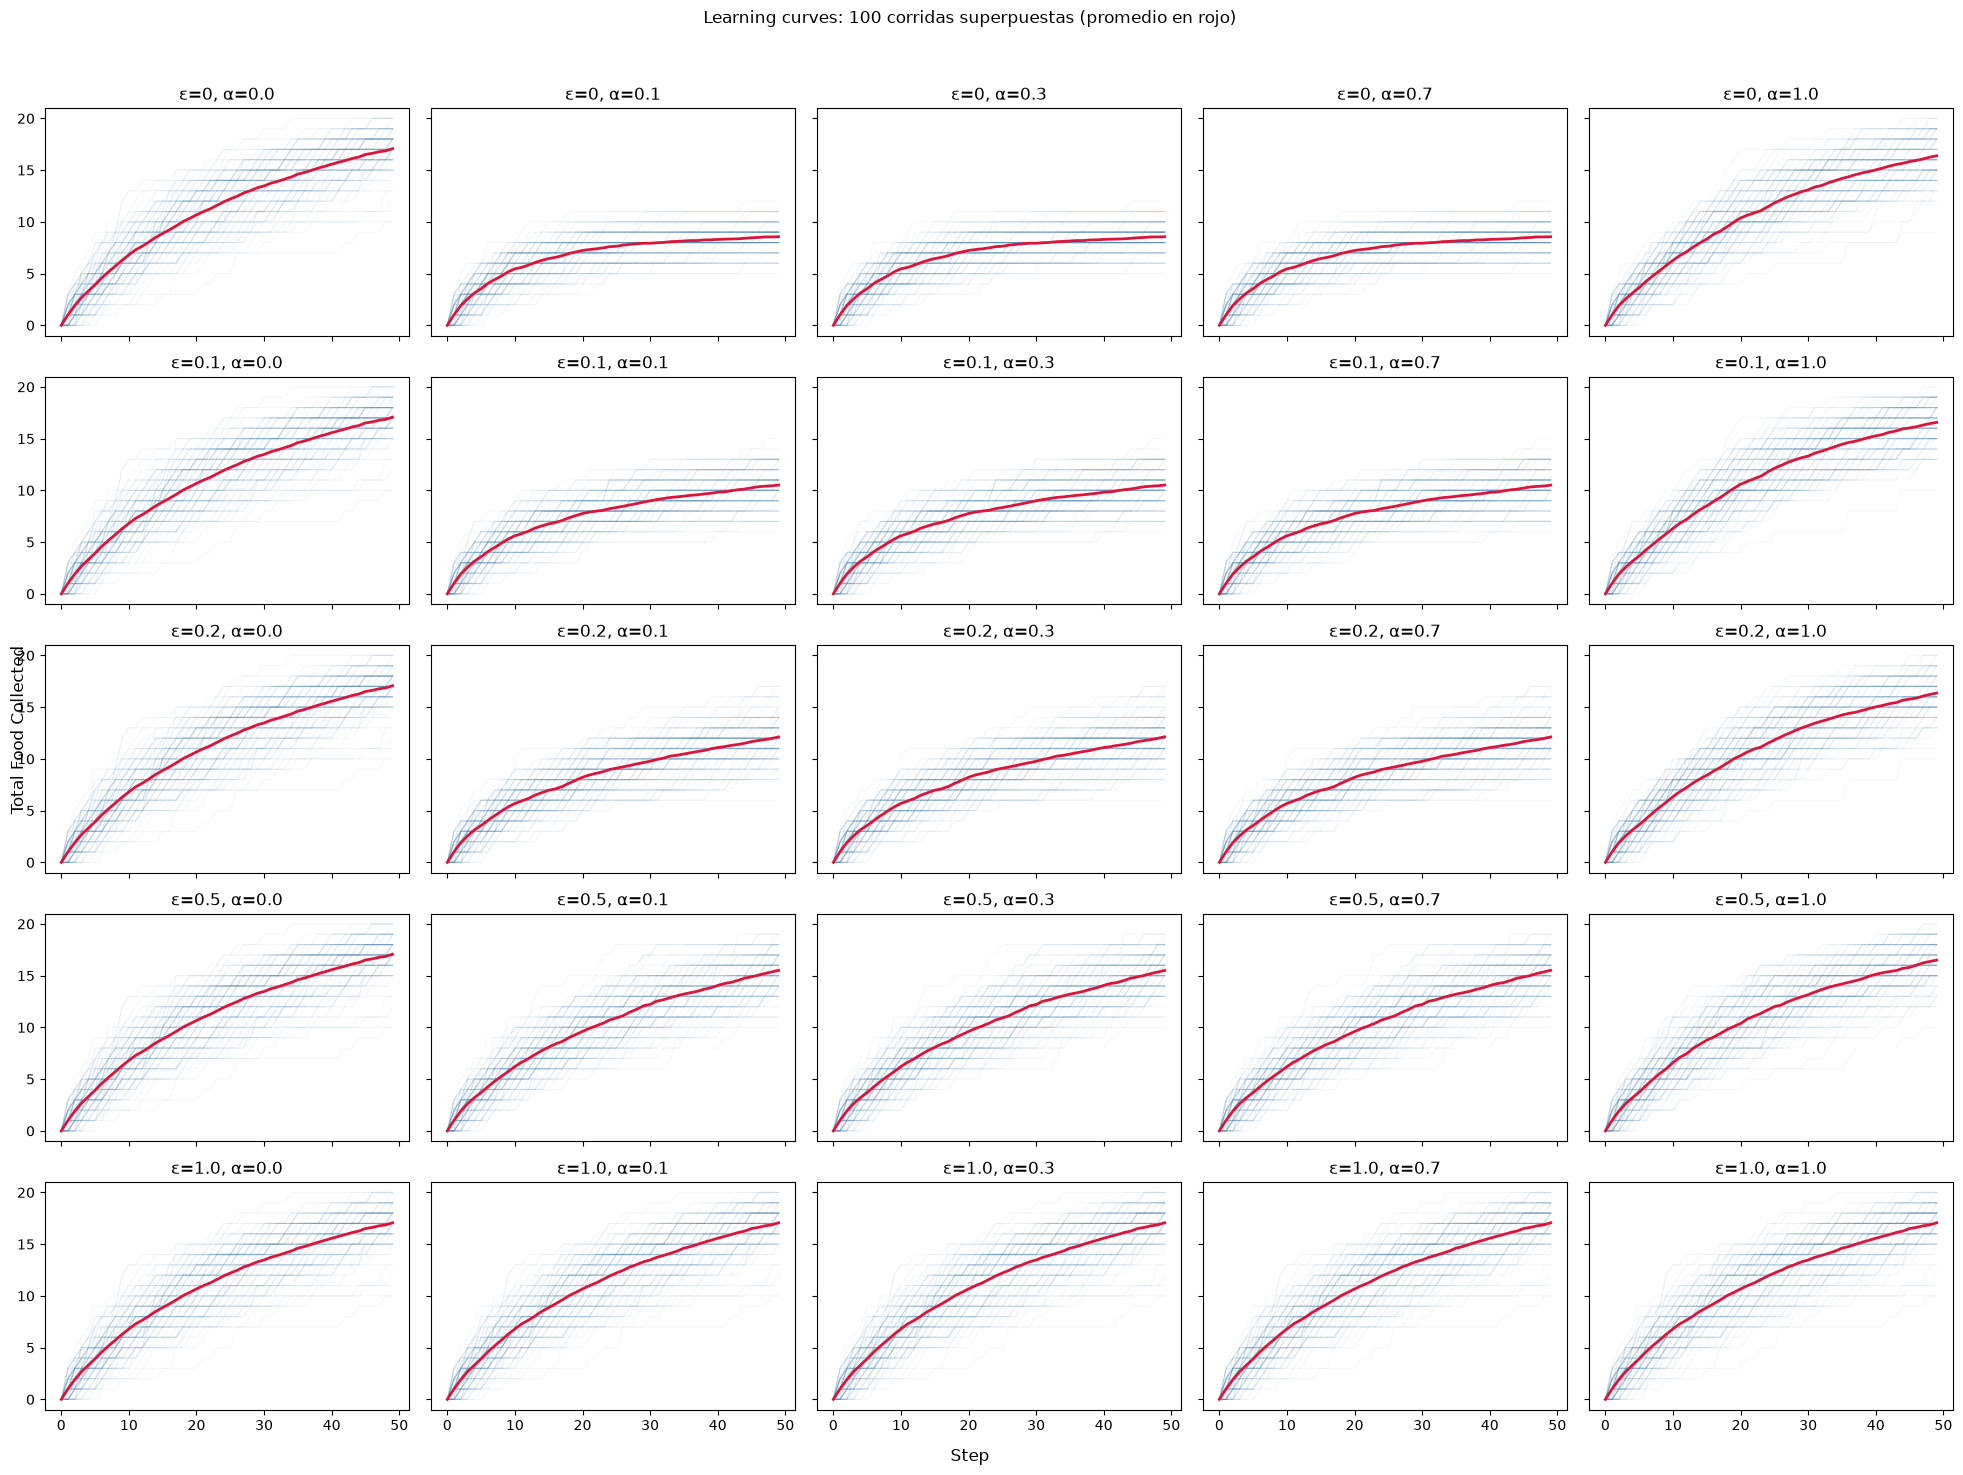

In [45]:
# -----------------------------
# Visualización: corridas superpuestas
# -----------------------------
fig, axes = plt.subplots(
    len(epsilon_values),
    len(alpha_values),
    figsize=(4 * len(alpha_values), 3 * len(epsilon_values)),
    sharex=True,
    sharey=True,
)

for i, eps in enumerate(epsilon_values):
    for j, a in enumerate(alpha_values):
        curves = results[eps][a]
        ax = axes[i, j]

        for curve in curves:
            ax.plot(curve, color="steelblue", alpha=0.06, linewidth=0.8)

        ax.plot(curves.mean(axis=0), color="crimson", linewidth=2)
        ax.set_title(f"ε={eps}, α={a}")

fig.suptitle(f"Learning curves: {RUNS} corridas superpuestas (promedio en rojo)")
fig.supxlabel("Step")
fig.supylabel("Total Food Collected")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


¿Cómo depende el comportamiento de la curva de los parámetros iniciales e
psilon y alpha?

Ejercicios propuestos:

* Curva de aprendizaje repetida: correr LearningModel varias veces (5–10 corridas) con los mismos parámetros y graficar todas las curvas de TotalScore superpuestas. ¿La curva siempre sube igual, o hay mucha variabilidad entre corridas?
* Barrido de epsilon: fijar alpha=0.3 y comparar el desempeño para epsilon ∈ {0, 0.1, 0.2, 0.5, 1.0}. Observar el comportamiento.
* Barrido de alpha: mismo ejercicio pero variando alpha ∈ {0.05, 0.1, 0.3, 0.7, 1.0} con epsilon fijo. ¿Qué pasa con alpha=1? (pista: mirar update_q — con alpha=1 el agente olvida por completo el valor anterior de esa celda).
* Registrar la memoria de valores: agregar un model_reporter o agent_reporter al DataCollector que guarde, por ejemplo, len(agent.q_values) para ver cuántas celdas distintas ha "aprendido" cada agente con el tiempo.
* Decaimiento de epsilon: modificar step() para que self.epsilon disminuya gradualmente (por ejemplo epsilon *= 0.99 cada paso). Comparar la curva de aprendizaje con la versión de epsilon constante. Esto introduce la idea de pasar de exploración a explotación con el tiempo, un concepto estándar en aprendizaje por refuerzo.
* Reposición de comida: actualmente food_list solo disminuye. Modificar LearningModel.step() para que, con cierta probabilidad, aparezca comida nueva en una celda aleatoria. ¿Cambia la forma de la curva de aprendizaje (por ejemplo, deja de estabilizarse)?
* Castigo además de recompensa: modificar get_reward() para que el agente reciba una pequeña recompensa negativa (por ejemplo -0.01) en cada paso donde no encuentra comida, simulando "costo de energía" por moverse. Comparar cómo cambia la estrategia aprendida.